# NN_L12_agreement

**Accuracy of TF-IDF with logistic regression and of zero-shot and few-shot Qwen2.5-3B on Financial PhraseBank sentences by annotator agreement (100, 75, 66 and 50 percent).**

Neural Networks and Deep Learning (NN), Lecture 12 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L12/NN_L12_agreement/NN_L12_agreement.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

tfidf accuracy at 100 % agreement = 90.3   [agree.tfidf.100]
tfidf accuracy at 75 % agreement = 72.8   [agree.tfidf.75]
tfidf accuracy at 66 % agreement = 54.5   [agree.tfidf.66]
tfidf accuracy at 50 % agreement = 54.9   [agree.tfidf.50]
zs_3B accuracy at 100 % agreement = 93.1   [agree.zs_3B.100]
zs_3B accuracy at 75 % agreement = 77.2   [agree.zs_3B.75]
zs_3B accuracy at 66 % agreement = 65.7   [agree.zs_3B.66]
zs_3B accuracy at 50 % agreement = 53.7   [agree.zs_3B.50]
fs_3B accuracy at 100 % agreement = 93.4   [agree.fs_3B.100]
fs_3B accuracy at 75 % agreement = 80.5   [agree.fs_3B.75]
fs_3B accuracy at 66 % agreement = 65.1   [agree.fs_3B.66]
fs_3B accuracy at 50 % agreement = 58.2   [agree.fs_3B.50]


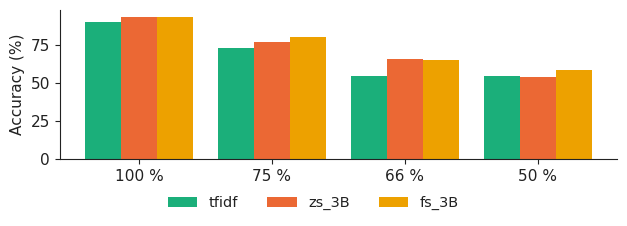

In [3]:
RES = REPO + 'lectures/L12/results/'
import json, urllib.request
def load_json(name):
    p = RES + name
    return json.load(open(p)) if os.path.exists(p) else json.load(urllib.request.urlopen(p))
from sklearn.metrics import f1_score, accuracy_score
LAB = {'pb': ['positive', 'negative', 'neutral'], 'tw': ['bullish', 'bearish', 'neutral']}
def f1(y, p, ds):
    return f1_score(y, p, labels=LAB[ds], average='macro')
def pred(df, m, ds):
    P = df[[f'{m}_{l}' for l in LAB[ds]]].values
    return [LAB[ds][i] for i in P.argmax(1)]
A = pd.read_csv(RES + 'agreement_labels.csv')
T = pd.read_csv(RES + 'predictions_pb.csv')
acc = {}
for m, mt in (('tfidf', 'tfidf'), ('zs_3B', 'zs_3B'), ('fs_3B', 'fs_3B')):
    acc[(m, 100)] = 100 * accuracy_score(T.label, pred(T, mt, 'pb'))
    for lev in (75, 66, 50):
        s = A[A.agreement == lev]
        acc[(m, lev)] = 100 * accuracy_score(s.label, s[m])
    for lev in (100, 75, 66, 50):
        show(f'agree.{m}.{lev}', f'{m} accuracy at {lev} % agreement', round(acc[(m, lev)], 1))
fig, ax = plt.subplots(figsize=(6.4, 2.3))
for j, (m, c) in enumerate((('tfidf', PAL['benchmark']), ('zs_3B', PAL['model']), ('fs_3B', PAL['alt']))):
    ax.bar(np.arange(4) + (j - 1) * 0.27, [acc[(m, l)] for l in (100, 75, 66, 50)], 0.27, color=c, label=m)
ax.set_xticks(range(4))
ax.set_xticklabels(['100 %', '75 %', '66 %', '50 %'])
ax.set_ylabel('Accuracy (%)')
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('agreement.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()